## Figure 2: Complaint Composition Varies Across Vehicle Models

This analysis compares the distribution of reported vehicle components across all 10 vehicle models using a heatmap.

We use component complaint percentages rather than raw counts to account for differences in total complaint volume across models. Complaints involving multiple components will be handled using a consistent counting method.

The goal is to identify component-specific patterns that may provide useful features for predicting future NHTSA safety investigations.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[1]
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "complaints_clean.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (9461, 15)


,complaint_id,make,model,model_year,product_model,filed_date,incident_date,components,crash,fire,number_of_injuries,number_of_deaths,summary,reporting_delay,invalid_incident_date
0,11770133,TOYOTA,CAMRY,2018,CAMRY,2026-10-09,2026-09-29,POWER TRAIN,False,False,0,0,"Total transmission failure at about 107,770 mi...",10.0,False
1,11769969,TOYOTA,CAMRY,2018,CAMRY,2026-10-08,2026-10-06,ENGINE,False,False,0,0,My 2018 Toyota Camry LE went into Limp mode wh...,2.0,False
2,11769124,TOYOTA,CAMRY,2018,CAMRY,2026-10-05,2026-10-03,POWER TRAIN,False,False,0,0,The contact owns a 2018 Toyota Camry. The cont...,2.0,False
3,11768868,TOYOTA,CAMRY,2018,CAMRY,2026-10-04,2026-10-02,FUEL/PROPULSION SYSTEM,False,False,0,0,I am filing a formal complaint regarding a sev...,2.0,False
4,11768335,TOYOTA,CAMRY,2018,CAMRY,2026-10-01,2026-09-29,POWER TRAIN,False,False,0,0,"2018 Toyota Camry approx 126,000 miles. Trans...",2.0,False


In [11]:
import re

component_categories = [
    "ENGINE",
    "POWER TRAIN",
    "ELECTRICAL SYSTEM",
    "SERVICE BRAKES",
    "STEERING",
    "STRUCTURE",
    "AIR BAGS",
    "FUEL/PROPULSION SYSTEM",
    "VEHICLE SPEED CONTROL",
    "FORWARD COLLISION AVOIDANCE"
]

component_df = df.copy()

component_df["vehicle"] = (
    component_df["make"] + " " + component_df["model"]
)

for component in component_categories:
    pattern = (
        r"(?<![A-Z0-9])"
        + re.escape(component)
        + r"(?![A-Z0-9])"
    )

    component_df[component] = (
        component_df["components"]
        .fillna("")
        .str.contains(pattern, regex=True)
    )

component_percent = (
    component_df
    .groupby("vehicle")[component_categories]
    .mean()
    .mul(100)
)

display(component_percent.round(1))

,ENGINE,POWER TRAIN,ELECTRICAL SYSTEM,SERVICE BRAKES,STEERING,STRUCTURE,AIR BAGS,FUEL/PROPULSION SYSTEM,VEHICLE SPEED CONTROL,FORWARD COLLISION AVOIDANCE
vehicle,,,,,,,,,,
AUDI Q5,16.2,6.3,33.1,10.9,7.4,9.2,5.6,2.1,7.4,9.5
BMW 3 SERIES,32.0,6.5,26.8,3.3,2.6,2.0,7.8,7.8,3.9,3.3
FORD ESCAPE,49.8,16.3,6.4,2.0,1.6,16.2,0.8,3.5,1.3,2.0
FORD F-150,16.1,75.0,7.8,3.6,2.6,1.6,0.5,0.5,2.1,3.1
HONDA CIVIC,7.4,4.9,10.3,5.1,28.5,3.1,4.8,13.3,1.4,4.5
HYUNDAI ELANTRA,49.8,10.4,13.6,4.4,5.7,3.2,2.4,3.9,3.8,2.8
MERCEDES-BENZ C-CLASS,26.3,8.2,12.2,3.9,8.2,12.5,3.9,8.2,2.0,3.9
NISSAN ALTIMA,17.6,7.8,22.0,15.1,5.5,2.5,8.8,3.3,4.1,13.3
TOYOTA CAMRY,20.1,24.3,11.4,15.4,5.4,2.0,6.7,12.3,7.3,5.6


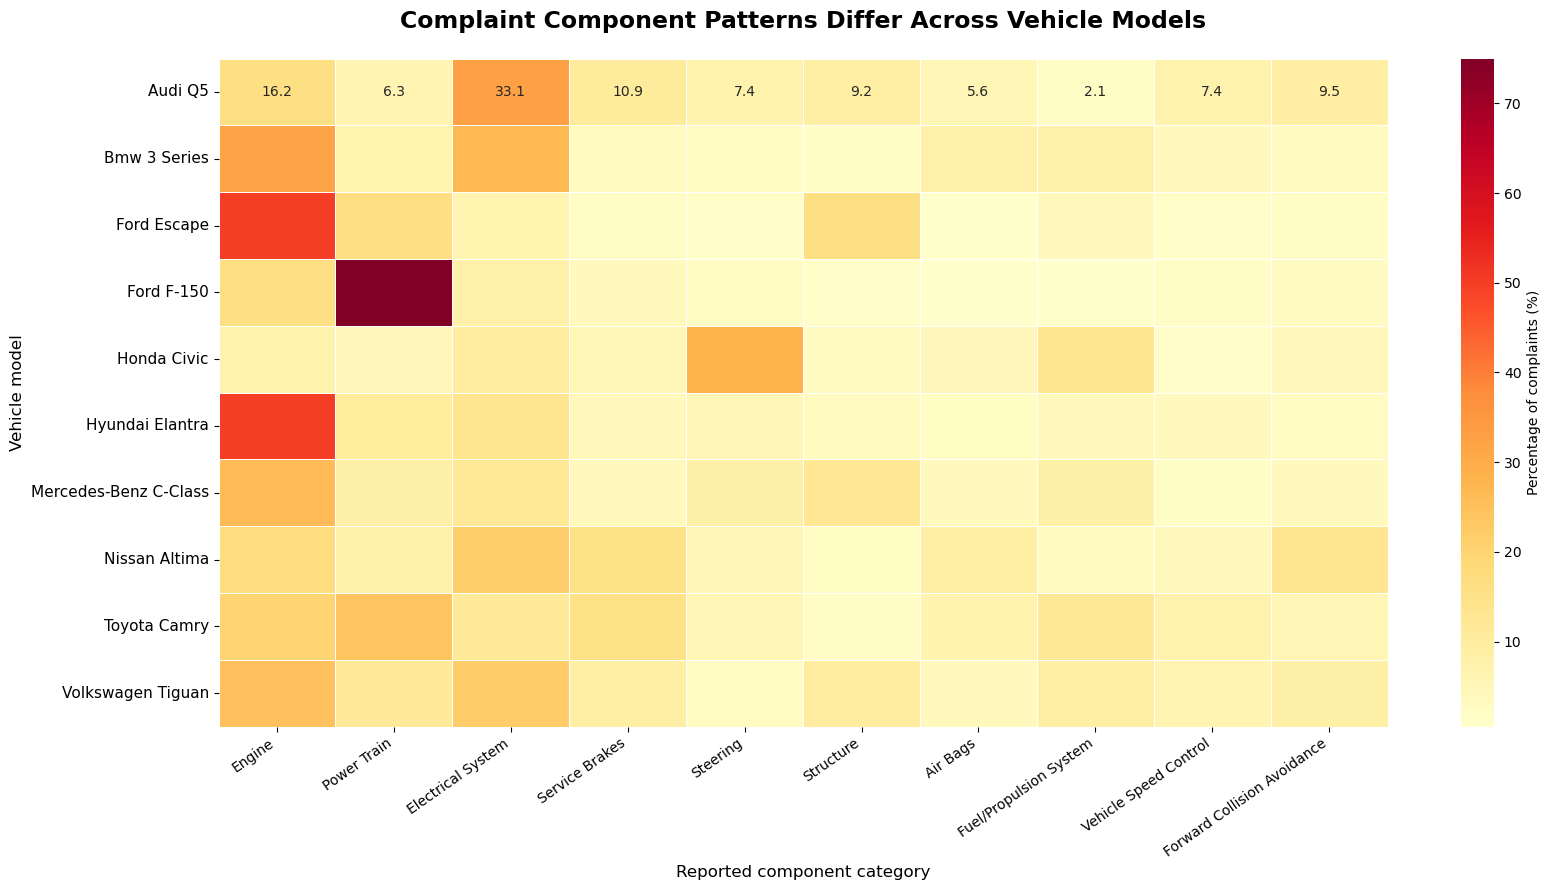

In [13]:
# Figure 2: Component Complaint Heatmap

import matplotlib.pyplot as plt
import seaborn as sns

# Make vehicle names easier to read
component_plot = component_percent.copy()

component_plot.index = component_plot.index.str.title()

# Improve component labels
component_plot.columns = [
    name.title() for name in component_plot.columns
]

plt.figure(figsize=(17, 9))

ax = sns.heatmap(
    component_plot,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.6,
    linecolor="white",
    cbar_kws={
        "label": "Percentage of complaints (%)"
    },
    annot_kws={"size": 10}
)

ax.set_title(
    "Complaint Component Patterns Differ Across Vehicle Models",
    fontsize=17,
    fontweight="bold",
    pad=22
)

ax.set_xlabel("Reported component category", fontsize=12)
ax.set_ylabel("Vehicle model", fontsize=12)

plt.xticks(rotation=35, ha="right", fontsize=10)
plt.yticks(rotation=0, fontsize=11)

plt.tight_layout()

plt.savefig(
    PROJECT_ROOT / "figures" / "component_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Key Findings

- Different vehicle models show different patterns in the types of components reported in complaints.
- Ford Escape and Hyundai Elantra have a high percentage of engine-related complaints (49.8%), while Ford F-150 has a particularly high percentage of power train complaints (75.0%).
- Steering complaints are more common for Honda Civic (28.5%), while Audi Q5 has a higher percentage of electrical system complaints (33.1%).
- These differences suggest that complaint types, rather than just total complaint counts, could be useful for predicting future safety investigations.